# Role&Context

Publication-oriented descriptive visualizations of the developer survey. Each notebook reads the Excel workbook from **the same folder as the notebook** and saves vector PDFs and high-resolution PNGs under `figures/role_context/`.

- The source workbook is not modified.
- Frequencies are calculated from the data at execution time (not hard-coded).
- For single-choice questions, percentages use valid responses to that question; missing answers are reported separately.
- For multi-select questions, percentages are percentages of respondents, so they need **not** sum to 100%.
- Category labels are taken directly from the survey; manual recoding is avoided.


In [1]:
FOLDER = 'role_context'
from pathlib import Path
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, PercentFormatter

# Put the original .xlsx alongside this notebook.
EXCEL_FILE = None  # Optionally specify a filename, e.g. "survey.xlsx"
ROOT = Path.cwd()
files = sorted(p for p in ROOT.glob("*.xlsx") if not p.name.startswith("~$"))
if EXCEL_FILE is None:
    if len(files) != 1:
        raise FileNotFoundError(f"Expected exactly one .xlsx alongside the notebook, found {len(files)}: {[p.name for p in files]}. Set EXCEL_FILE above.")
    excel_path = files[0]
else:
    excel_path = ROOT / EXCEL_FILE
raw = pd.read_excel(excel_path)
N = len(raw)
FIG_DIR = ROOT / "figures" / FOLDER
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Restrained, colorblind-conscious palette. All charts use the same styling.
INK = '#202a34'
BLUE = '#396ba4'
TEAL = '#368a82'
PALE = '#e7ebef'
PALETTE = ['#4878a8', '#6c91b6', '#8bb7ad', '#d9b26f', '#ba7383', '#857cae', '#8e9eab']
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 9.5, 'axes.labelsize': 9.5,
    'axes.titlesize': 11, 'axes.titleweight': 'semibold',
    'axes.edgecolor': '#bfc6ce', 'axes.labelcolor': INK,
    'text.color': INK, 'xtick.color': INK, 'ytick.color': INK,
    'axes.spines.top': False, 'axes.spines.right': False,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'savefig.facecolor': 'white', 'pdf.fonttype': 42, 'ps.fonttype': 42,
})

def col(index):
    """Index is from the original workbook (0-based), to avoid ambiguity in long survey questions."""
    return raw.iloc[:, index]

def wrap(value, width=43):
    return '\n'.join(textwrap.wrap(str(value), width=width, break_long_words=False, break_on_hyphens=False))

def save_plot(fig, slug):
    for ext in ('pdf', 'png'):
        fig.savefig(FIG_DIR / f'{slug}.{ext}', bbox_inches='tight',
                    dpi=350 if ext == 'png' else None, pad_inches=0.16)
    plt.show()
    plt.close(fig)

def single(index, title, slug, order=None, labels=None):
    series = col(index).dropna().astype(str).str.strip()
    counts = series.value_counts()
    if order is not None:
        counts = counts.reindex([key for key in order if key in counts.index], fill_value=0)
        other = series.value_counts().drop(index=counts.index, errors='ignore')
        counts = pd.concat([counts, other])
    if labels is not None:
        counts.index = [labels.get(k, k) for k in counts.index]
    denom = len(series)
    values = 100 * counts / denom
    labels_wrapped = [wrap(k) for k in counts.index]
    fig, ax = plt.subplots(figsize=(8.4, max(2.7, len(counts)*0.52 + 0.7)))
    pos = np.arange(len(counts))
    ax.barh(pos, values, color=BLUE, height=.69)
    ax.set_yticks(pos, labels_wrapped)
    ax.invert_yaxis()
    ax.set_xlim(0, max(30, np.ceil(values.max()/10)*10 + 12))
    ax.set_xlabel('Respondents (%)')
    ax.set_title(title, loc='left', pad=14)
    ax.xaxis.set_major_locator(MultipleLocator(20))
    ax.grid(axis='x', color=PALE, lw=.7)
    ax.set_axisbelow(True)
    ax.tick_params(axis='y', length=0, pad=8)
    for i, (pct, count) in enumerate(zip(values, counts)):
        ax.text(pct + 0.8, i, f'{pct:.1f}%  (n={count})', va='center', fontsize=8.1)
    fig.text(.99, .005, f'Valid n={denom}; missing n={N-denom}', ha='right', fontsize=8, color='#5d6872')
    fig.tight_layout(rect=(0, .025, 1, 1))
    save_plot(fig, slug)
    return counts

def multiple(index, title, slug, top=None):
    valid = col(index).dropna().astype(str)
    # Survey exports use comma-space delimiters for checkbox items.
    choices = valid.apply(lambda s: list(dict.fromkeys(x.strip() for x in s.split(', ') if x.strip())))
    counts = pd.Series([choice for row in choices for choice in row]).value_counts()
    if top is not None:
        counts = counts.head(top)
    counts = counts.sort_values()
    vals = counts * 100 / len(valid)
    fig, ax = plt.subplots(figsize=(9.0, max(3.1, len(counts)*.37 + .85)))
    y = np.arange(len(counts))
    ax.barh(y, vals, color=TEAL, height=.73)
    ax.set_yticks(y, [wrap(s, 46) for s in counts.index])
    ax.tick_params(axis='y', length=0, pad=8)
    ax.set_xlim(0, max(30, np.ceil(vals.max()/10)*10 + 10))
    ax.set_xlabel('Respondents selecting the option (%)')
    ax.set_title(title, loc='left', pad=14)
    ax.xaxis.set_major_locator(MultipleLocator(20))
    ax.grid(axis='x', color=PALE, lw=.7)
    ax.set_axisbelow(True)
    for i, (v, count) in enumerate(zip(vals, counts)):
        ax.text(v + .75, i, f'{v:.1f}% (n={count})', va='center', fontsize=8)
    fig.text(.99, .005, f'Multiple selections permitted; valid n={len(valid)}; missing n={N-len(valid)}',
             ha='right', fontsize=8, color='#5d6872')
    fig.tight_layout(rect=(0, .026, 1, 1))
    save_plot(fig, slug)
    return counts

# print(f'Workbook: {excel_path.name} | Respondents: {N} | Output: {FIG_DIR}')
print(f'Workbook: {excel_path.name} | Respondents: {N}')



Workbook: developers-answers.xlsx | Respondents: 104


## Professional role

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


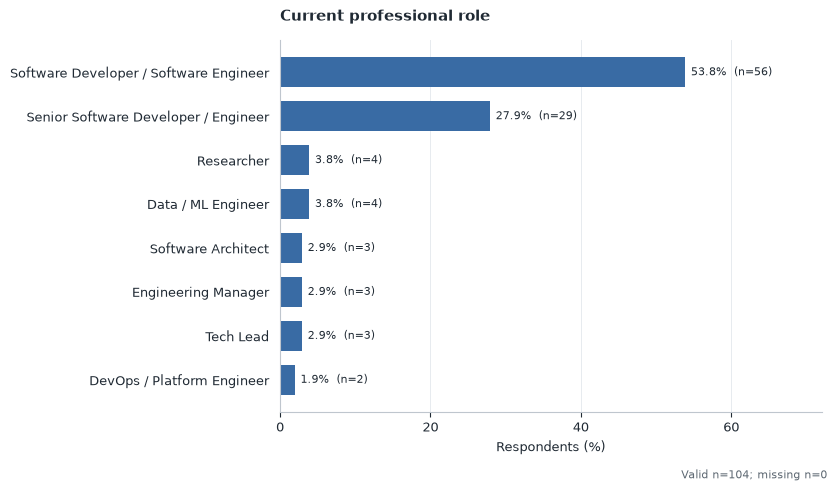

Which of the following best describes your current role?
Software Developer / Software Engineer    56
Senior Software Developer / Engineer      29
Researcher                                 4
Data / ML Engineer                         4
Software Architect                         3
Engineering Manager                        3
Tech Lead                                  3
DevOps / Platform Engineer                 2
Name: count, dtype: int64

In [2]:
single(2, 'Current professional role', 'professional_role')

## Professional experience

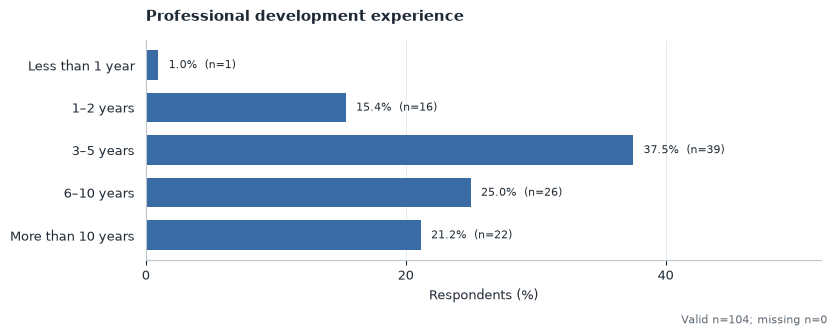

How many years of professional software development experience do you have?
Less than 1 year       1
1–2 years             16
3–5 years             39
6–10 years            26
More than 10 years    22
Name: count, dtype: int64

In [3]:
single(3, 'Professional development experience', 'experience', order=['Less than 1 year','1–2 years','3–5 years','6–10 years','More than 10 years'])

## Work context

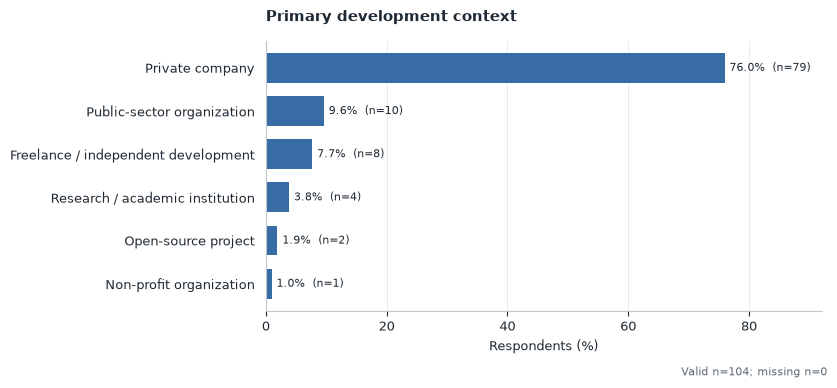

In which context do you primarily develop software?
Private company                        79
Public-sector organization             10
Freelance / independent development     8
Research / academic institution         4
Open-source project                     2
Non-profit organization                 1
Name: count, dtype: int64

In [4]:
single(5, 'Primary development context', 'work_context')

## Application domains (multiple selections)

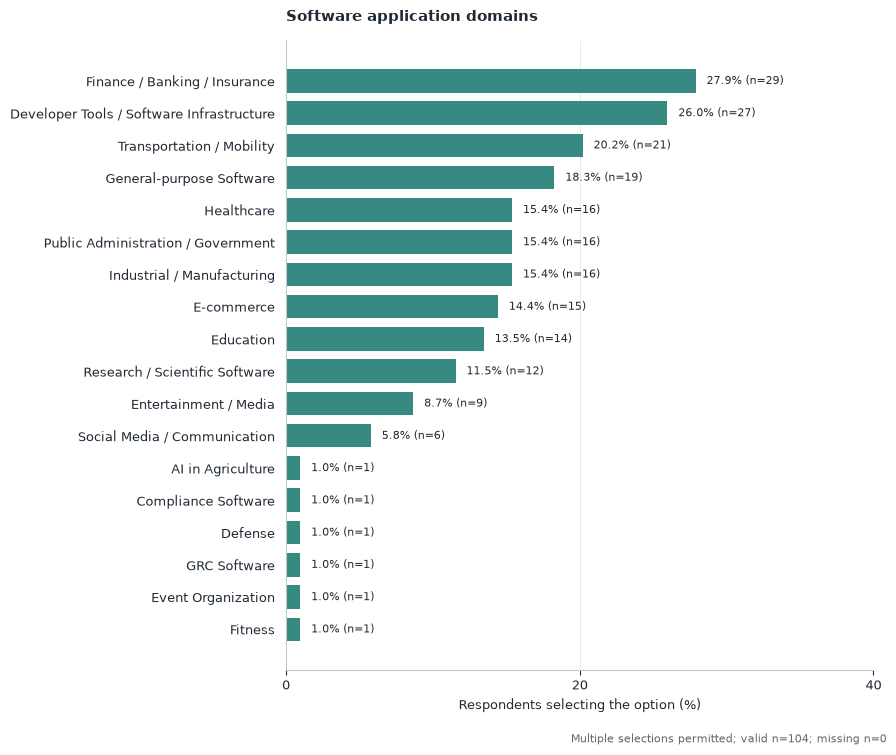

Fitness                                       1
Event Organization                            1
GRC Software                                  1
Defense                                       1
Compliance Software                           1
AI in Agriculture                             1
Social Media / Communication                  6
Entertainment / Media                         9
Research / Scientific Software               12
Education                                    14
E-commerce                                   15
Industrial / Manufacturing                   16
Public Administration / Government           16
Healthcare                                   16
General-purpose Software                     19
Transportation / Mobility                    21
Developer Tools / Software Infrastructure    27
Finance / Banking / Insurance                29
Name: count, dtype: int64

In [5]:
multiple(6, 'Software application domains', 'application_domains')

## Development areas (multiple selections)

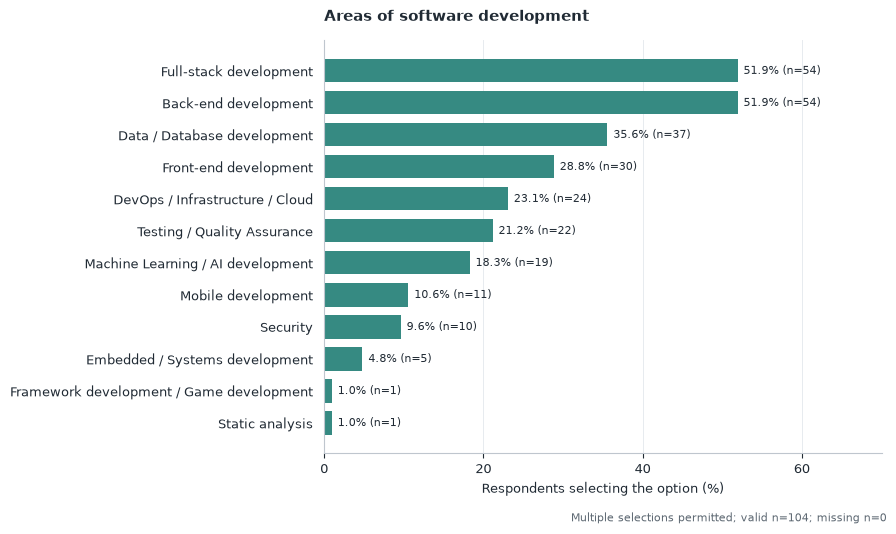

Static analysis                              1
Framework development / Game development     1
Embedded / Systems development               5
Security                                    10
Mobile development                          11
Machine Learning / AI development           19
Testing / Quality Assurance                 22
DevOps / Infrastructure / Cloud             24
Front-end development                       30
Data / Database development                 37
Back-end development                        54
Full-stack development                      54
Name: count, dtype: int64

In [6]:
multiple(7, 'Areas of software development', 'development_areas')

## Target users (multiple selections)

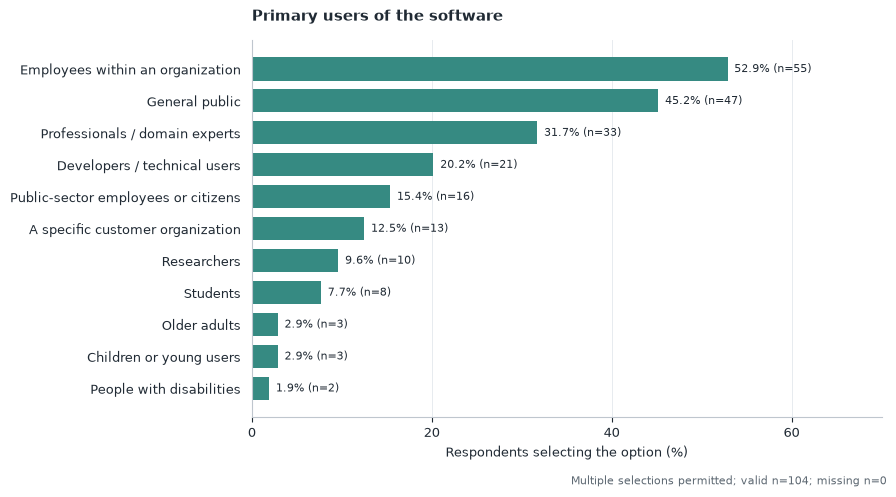

People with disabilities                2
Children or young users                 3
Older adults                            3
Students                                8
Researchers                            10
A specific customer organization       13
Public-sector employees or citizens    16
Developers / technical users           21
Professionals / domain experts         33
General public                         47
Employees within an organization       55
Name: count, dtype: int64

In [7]:
multiple(8, 'Primary users of the software', 'primary_users')

## Team size

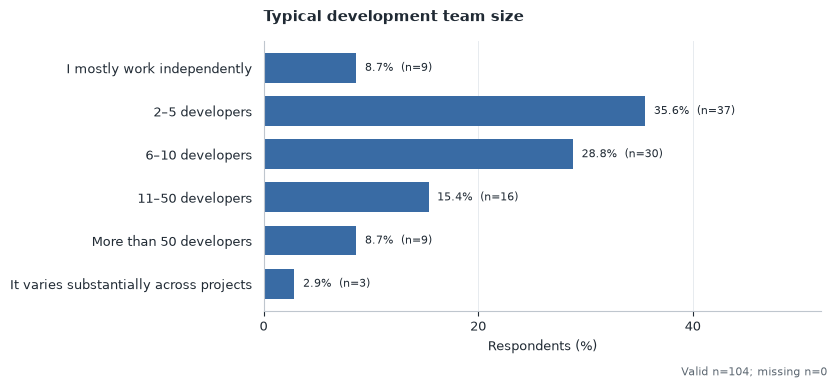

Approximately how large is the development team you usually work with?
I mostly work independently                 9
2–5 developers                             37
6–10 developers                            30
11–50 developers                           16
More than 50 developers                     9
It varies substantially across projects     3
Name: count, dtype: int64

In [8]:
single(9, 'Typical development team size', 'team_size', order=['I mostly work independently','2–5 developers','6–10 developers','11–50 developers','More than 50 developers','It varies substantially across projects'])

## Location responses

In [9]:
# Company location is free text (cities, countries, mixed formats).
# Avoid unreliable automatic country inference; report coverage, without geocoding.
location = col(4).dropna().astype(str).str.strip()
print(f'Location responses: {len(location)}/{N}; distinct verbatim responses: {location.nunique()}')
print('For country-level plots, create an audited location-to-country mapping before visualization.')

Location responses: 104/104; distinct verbatim responses: 86
For country-level plots, create an audited location-to-country mapping before visualization.


**Reproducibility note.** Outputs are descriptive (no inferential statistics). Text responses are intentionally not treated as quantitative categories; the plots only aggregate closed-ended questions. Denominators and missing-response counts are shown in each figure.